In [6]:
import pandas as pd
from pathlib import Path

RAW = Path("../data/raw")

df = pd.read_csv(
    RAW / "dga_dataset.csv",
    sep=";",
    decimal=","
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4150, 6)


,H2,CH4,C2H6,C2H4,C2H2,Fail
0,345.0,112.3,27.5,51.5,58.800,D1
1,181.0,262.0,41.0,28.0,0.001,T1
2,172.9,334.0,172.0,812.5,37.700,T3
3,127.0,107.0,11.0,154.0,224.000,D2
4,60.0,40.0,6.9,110.0,70.000,D2


In [7]:
GAS = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]

LABEL = "Fail"

print(df.columns.tolist())

missing = [c for c in GAS + [LABEL] if c not in df.columns]

assert not missing, f"Fix these names to match your file: {missing}"

df.info()

['H2', 'CH4', 'C2H6', 'C2H4', 'C2H2', 'Fail']
<class 'pandas.DataFrame'>
RangeIndex: 4150 entries, 0 to 4149
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   H2      4150 non-null   float64
 1   CH4     4150 non-null   float64
 2   C2H6    4150 non-null   float64
 3   C2H4    4150 non-null   float64
 4   C2H2    4150 non-null   float64
 5   Fail    4150 non-null   str    
dtypes: float64(5), str(1)
memory usage: 194.7 KB


In [8]:
clean = df[LABEL].astype(str).str.strip().str.upper()

print(clean.value_counts().to_string())

print(
    "Unique before:", df[LABEL].nunique(),
    "| after trivial cleanup:", clean.nunique()
)

Fail
T3    879
D2    770
NF    740
D1    598
T1    463
PD    351
T2    349
Unique before: 31 | after trivial cleanup: 7


In [9]:
print("Fully identical rows:", df.duplicated().sum())

print(
    "Rows with identical gas values (any label):",
    df.duplicated(subset=GAS).sum()
)

n_labels = df.groupby(GAS)[LABEL].nunique()

print(
    "Gas profiles with conflicting labels:",
    (n_labels > 1).sum()
)

Fully identical rows: 1391
Rows with identical gas values (any label): 1431
Gas profiles with conflicting labels: 40


In [10]:
print(
    df[GAS].describe(
        percentiles=[.5, .9, .99, .999]
    ).T.round(1)
)

print("All-zero rows:", (df[GAS] == 0).all(axis=1).sum())

suspicious = df[(df[GAS] > 100_000).any(axis=1)]

print("Rows with any gas > 100,000:", len(suspicious))

suspicious

       count    mean     std  min   50%     90%      99%    99.9%      max
H2    4150.0  1142.1  5696.7  0.0  74.8  1550.0  26788.0  92600.0  92600.0
CH4   4150.0   651.9  3611.5  0.0  49.0   904.7  10500.0  64064.0  64064.0
C2H6  4150.0   364.8  3345.3  0.0  25.0   323.0   4790.0  72128.0  72128.0
C2H4  4150.0   736.6  4797.8  0.0  28.4   820.0  13500.0  95650.0  95650.0
C2H2  4150.0   396.4  2991.8  0.0   2.0   350.5   6432.0  57000.0  57000.0
All-zero rows: 0
Rows with any gas > 100,000: 0


,H2,CH4,C2H6,C2H4,C2H2,Fail


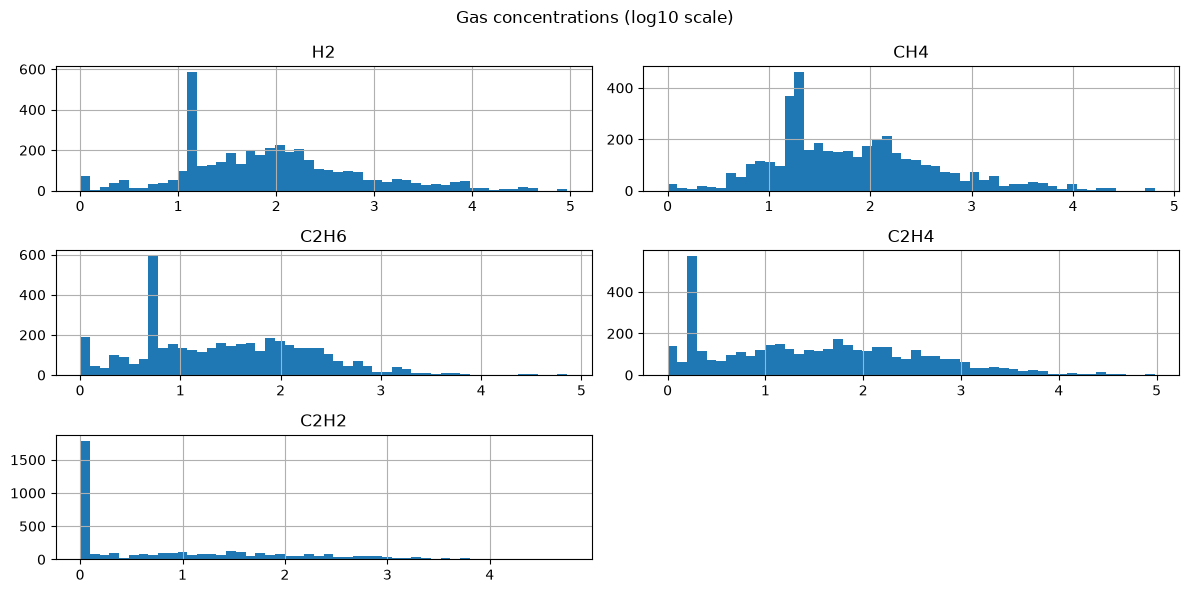

In [11]:
np.log10(df[GAS] + 1).hist(
    bins=50,
    figsize=(12, 6)
)

plt.suptitle("Gas concentrations (log10 scale)")

plt.tight_layout()

plt.show()

# DGA Dataset Audit Summary

1. Total number of labels before and after cleanup: Before: 31 | After : 7

2. Fully identical rows: 1391

3. Rows with identical gas values: 1431

4. Gas profiles with conflicting labels: 40

5. Number of suspicious rows: 0

6. Initial observations:
   - The dataset initially contained 31 unique labels, which were reduced to 7 labels after cleanup, indicating that label standardization was required.
   - 1,391 fully identical rows were identified, suggesting the presence of duplicate records that need to be removed.
   - 1,431 rows had identical gas values, including 40 cases with conflicting fault labels. These cases require careful inspection to ensure correct labeling.